# 2.6. Probability and Statistics

In [1]:
%matplotlib inline
import random
from matplotlib import pyplot as plt
import torch
from torch.distributions.multinomial import Multinomial

## 2.6.1. A Simple Example: Tossing Coins

In [2]:
num_tosses = 100
heads = sum([random.random() > 0.5 for _ in range(num_tosses)])
tails = num_tosses - heads
print("heads, tails:", [heads, tails])

heads, tails: [50, 50]


In [3]:
fair_probs = torch.tensor([0.5, 0.5])
Multinomial(100, fair_probs).sample()

tensor([52., 48.])

In [4]:
num_tosses = 100
Multinomial(num_tosses, fair_probs).sample() / num_tosses

tensor([0.5800, 0.4200])

In [5]:
num_tosses = 10000
counts = Multinomial(num_tosses, fair_probs).sample()
counts / num_tosses

tensor([0.5006, 0.4994])

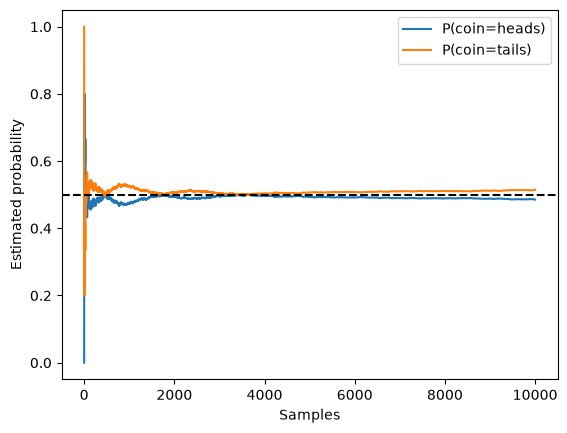

In [6]:
counts = Multinomial(1, fair_probs).sample((10000,))
cum_counts = counts.cumsum(dim=0)
estimates = cum_counts / cum_counts.sum(dim=1, keepdims=True)
estimates = estimates.numpy()

plt.plot(estimates[:, 0], label=("P(coin=heads)"))
plt.plot(estimates[:, 1], label=("P(coin=tails)"))
plt.axhline(y=0.5, color='black', linestyle='dashed')
plt.gca().set_xlabel('Samples')
plt.gca().set_ylabel('Estimated probability')
plt.legend()

## 2.6.5. An Example

Given that the overall probability of someone having HIV is $P(H=1)=0.0015$ and that the diagnostic $D_1$ gives the conditional probabilities:

| Conditional probability | $H=1$ | $H=0$ |
| --- | --- | --- |
| $P(D_1 = 1 | H)$ | 1 | 0.01 |
| $P(D_1 = 0 | H)$ | 0 | 0.99 |

In [7]:
from IPython.display import display, Math

pd11h1 = 1.0   # P(D_1 = 1 | H = 1)
pd11h0 = 0.01  # P(D_1 = 1 | H = 0)
pd10h1 = 0.0   # P(D_1 = 0 | H = 1)
pd10h0 = 0.99  # P(D_1 = 0 | H = 0)

ph1 = 0.0015
ph0 = 1 - ph1

The probability of diagnostic being positive is
$$
\begin{split}
P(D_1 = 1) &= P(D_1 = 1, H = 0) + P(D_1 = 1, H = 1) \\
&= P(D_1 = 1 | H = 0) P(H = 0) + P(D_1 = 1 | H = 1) P(H = 1)
\end{split}
$$

In [8]:
pd11 = pd11h0 * ph0 + pd11h1 * ph1

display(Math(r"P(D_1 = 1) = {}".format(pd11)))

<IPython.core.display.Math object>

The probability that a person has HIV given the positive diagnostic is

$$
P(H = 1 | D_1 = 1) = \frac{P(D_1 = 1 | H = 1) P(H = 1)}{P(D_1 = 1)}
$$

In [9]:
ph1d11 = pd11h1 * ph1 / pd11

display(Math(r"P(H = 1 | D_1 = 1) = {:.4f}".format(ph1d11)))

<IPython.core.display.Math object>

Second test $D_2$ (not as good as $D_1$):

| Conditional probability | $H=1$ | $H=0$ |
| --- | --- | --- |
| $P(D_2 = 1 | H)$ | 0.98 | 0.03 |
| $P(D_2 = 0 | H)$ | 0.02 | 0.97 |

Assuming conditional independence:

$$
P(D_1 = 1, D_2 = 1 | H = 0) = P(D_1 = 1 | H = 0) P(D_2 = 1 | H = 0),
$$

and

$$
P(D_1 = 1, D_2 = 1 | H = 1) = P(D_1 = 1 | H = 1) P(D_2 = 1 | H = 1).
$$

In [10]:
pd21h1 = 0.98
pd21h0 = 0.03
pd20h1 = 0.02
pd20h0 = 0.97

pd11d21h0 = pd11h0 * pd21h0

display(Math(r"P(D_1 = 1, D_2 = 1 | H = 0) = {}".format(pd11d21h0)))

<IPython.core.display.Math object>

In [11]:
pd11d21h1 = pd11h1 * pd21h1

display(Math(r"P(D_1 = 1, D_2 = 1 | H = 1) = {}".format(pd11d21h1)))

<IPython.core.display.Math object>

Now we can apply marginalization to obtain the probability that both tests come back positive:

$$
\begin{split}
P(D_1 = 1, D_2 = 2)
&= P(D_1 = 1, D_2 = 1, H = 0) + P(D_1 = 1, D_2 = 1, H = 1) \\
&= P(D_1 = 1, D_2 = 1 | H = 0) P(H = 0) + P(D_1 = 1, D_2 = 1 | H = 1) P(H = 1)
\end{split}
$$

In [12]:
pd11d21 = pd11d21h0 * ph0 + pd11d21h1 * ph1

display(Math(r"P(D_1 = 1, D_2 = 1) = {}".format(pd11d21)))

<IPython.core.display.Math object>

Finally, the probability of the patient having HIV given that both tests are positive is

$$
P(H = 1 | D_1 = 1, D_2 = 1) = \frac{P(D_1 = 1, D_2 = 1 | H = 1) P(H = 1)}{P(D_1 = 1, D_2 = 1)}
$$

In [13]:
ph1d11d21 = pd11d21h1 * ph1 / pd11d21

display(Math(r"P(H = 1 | D_1 = 1, D_2 = 1) = {:.4f}".format(ph1d11d21)))

<IPython.core.display.Math object>